# 05 — Model Evaluation

Evaluates the out-of-fold (OOF) predictions from notebook 04. Every prediction was made for a subject the model never saw during
training or tuning.

**Units of analysis.** Windows are not independent (≈ 58 per recording), so:
* point estimates are computed on all OOF windows (window level) and on recording means (recording level, 96 recordings);
* 95 % confidence intervals resample **subjects** with replacement (bootstrap, 1000 draws);
* statistical tests use one value per subject.

Positive class = **test (multitasking)**. Precision = P(test | predicted test); recall = sensitivity for test; specificity = recall for rest.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_curve, roc_auc_score, balanced_accuracy_score
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from joblib import Parallel, delayed

from data_loader import CHANNELS, CONDITIONS
from feature_extraction import feature_groups, channel_of
from modeling import model_specs, outer_cv, fixed_cv, decision_scores, score_threshold, SEED
from evaluation import classification_metrics, recording_level, per_subject, bootstrap_ci_by_subject

OUT = ROOT / "results" / "05_evaluation"; OUT.mkdir(parents=True, exist_ok=True)
FIG_DIR = ROOT / "results" / "figures" / "05_evaluation"; FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 170, "display.max_columns", 30)

table = pd.read_csv(ROOT / "data" / "features" / "features.csv.gz")
META_COLS = ["subject", "condition", "label", "start_s"]
meta, X = table[META_COLS], table.drop(columns=META_COLS)
y, groups = meta.label.values, meta.subject.values
P = pd.read_csv(ROOT / "results" / "04_modeling" / "oof_predictions.csv.gz")
MODELS = list(dict.fromkeys(P.model))
oof = {m: P[P.model == m].reset_index(drop=True)[["fold", "score", "pred"]] for m in MODELS}
thr = {m: (score_threshold(m) if m in model_specs() else 0.5) for m in MODELS}
for m in MODELS:
    assert (P[P.model == m].subject.values == meta.subject.values).all()  # row alignment
print("models:", MODELS)

models: ['classic_index', 'chance', 'logreg', 'svm_rbf', 'random_forest', 'grad_boost']


## 1. Metrics with subject-level confidence intervals

In [2]:
auc_fn = lambda g: roc_auc_score(g.label, g.score)
bacc_fn = lambda g: balanced_accuracy_score(g.label, g.pred)
rows, rec_tables = [], {}
for m in MODELS:
    o = oof[m]
    w = classification_metrics(y, o.pred, o.score)
    r = recording_level(meta, o, thr[m]); rec_tables[m] = r
    rm = classification_metrics(r.label, r.pred, r.score)
    ci_auc = bootstrap_ci_by_subject(meta, o, auc_fn) if m != "chance" else (0.5, 0.5)
    ci_bacc = bootstrap_ci_by_subject(meta, o, bacc_fn)
    rows.append({"model": m, **{f"win_{k}": v for k, v in w.items() if k not in ("confusion_matrix", "n")},
                 "win_auc_ci": ci_auc, "win_bal_acc_ci": ci_bacc,
                 "rec_accuracy": rm["accuracy"], "rec_auc": rm["roc_auc"], "rec_f1": rm["f1"],
                 "win_cm": w["confusion_matrix"], "rec_cm": rm["confusion_matrix"]})
metrics = pd.DataFrame(rows).set_index("model")
show = metrics[["win_accuracy", "win_balanced_accuracy", "win_precision", "win_recall", "win_specificity", "win_f1", "win_roc_auc", "rec_accuracy", "rec_auc"]]
display(show.round(3))
display(metrics[["win_auc_ci", "win_bal_acc_ci"]].map(lambda t: f"[{t[0]:.3f}, {t[1]:.3f}]"))

,win_accuracy,win_balanced_accuracy,win_precision,win_recall,win_specificity,win_f1,win_roc_auc,rec_accuracy,rec_auc
model,,,,,,,,,
classic_index,0.608,0.603,0.596,0.516,0.690,0.553,0.645,0.656,0.689
chance,0.530,0.500,0.000,0.000,1.000,0.000,0.472,0.500,0.502
logreg,0.801,0.800,0.786,0.792,0.809,0.789,0.881,0.865,0.957
svm_rbf,0.793,0.793,0.773,0.792,0.794,0.783,0.877,0.875,0.958
random_forest,0.802,0.801,0.787,0.794,0.809,0.790,0.877,0.885,0.951
grad_boost,0.791,0.793,0.752,0.829,0.758,0.789,0.863,0.865,0.928


,win_auc_ci,win_bal_acc_ci
model,,
classic_index,"[0.590, 0.701]","[0.561, 0.643]"
chance,"[0.500, 0.500]","[0.500, 0.500]"
logreg,"[0.838, 0.918]","[0.757, 0.841]"
svm_rbf,"[0.839, 0.911]","[0.751, 0.830]"
random_forest,"[0.837, 0.913]","[0.759, 0.838]"
grad_boost,"[0.812, 0.907]","[0.743, 0.838]"


## 2. Confusion matrices

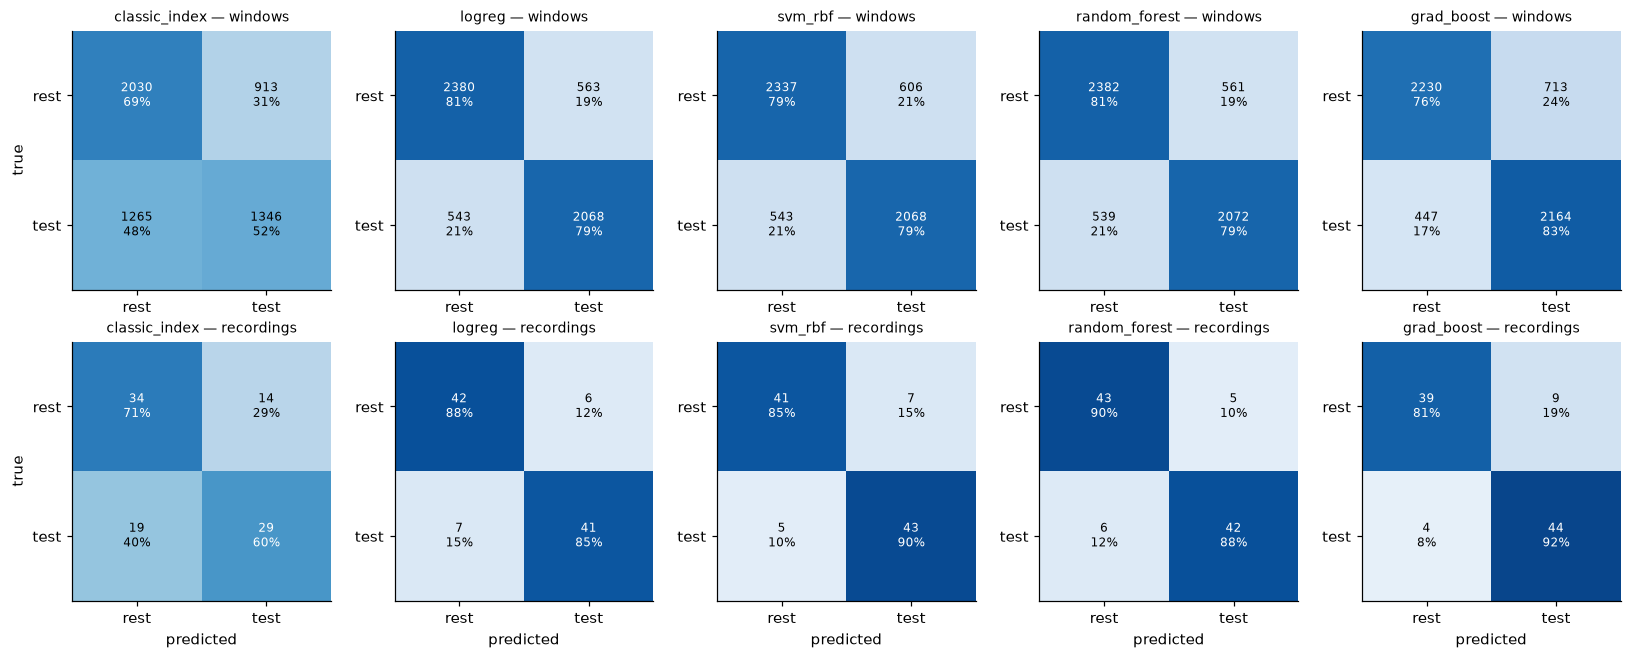

In [3]:
cand = [m for m in MODELS if m != "chance"]
fig, axes = plt.subplots(2, len(cand), figsize=(3.0 * len(cand), 6))
for j, m in enumerate(cand):
    for i, (lvl, key) in enumerate([("windows", "win_cm"), ("recordings", "rec_cm")]):
        cm = np.array(metrics.loc[m, key]); cmn = cm / cm.sum(1, keepdims=True)
        ax = axes[i, j]; ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1); ax.grid(False)
        for (a, b), v in np.ndenumerate(cm):
            ax.text(b, a, f"{v}\n{cmn[a, b]:.0%}", ha="center", va="center", fontsize=8, color="white" if cmn[a, b] > 0.6 else "black")
        ax.set_xticks([0, 1], ["rest", "test"]); ax.set_yticks([0, 1], ["rest", "test"])
        ax.set_title(f"{m} — {lvl}", fontsize=9)
        if j == 0: ax.set_ylabel("true")
        if i == 1: ax.set_xlabel("predicted")
fig.tight_layout(); fig.savefig(FIG_DIR / "confusion_matrices.png", bbox_inches="tight"); plt.show()

## 3. ROC curves

The ROC curve plots true-positive rate against false-positive rate as the decision threshold sweeps; AUC equals the probability that a randomly chosen
test window scores higher than a randomly chosen rest window (Mann–Whitney interpretation), so it is threshold-free and insensitive to the class imbalance
created by artifact rejection.

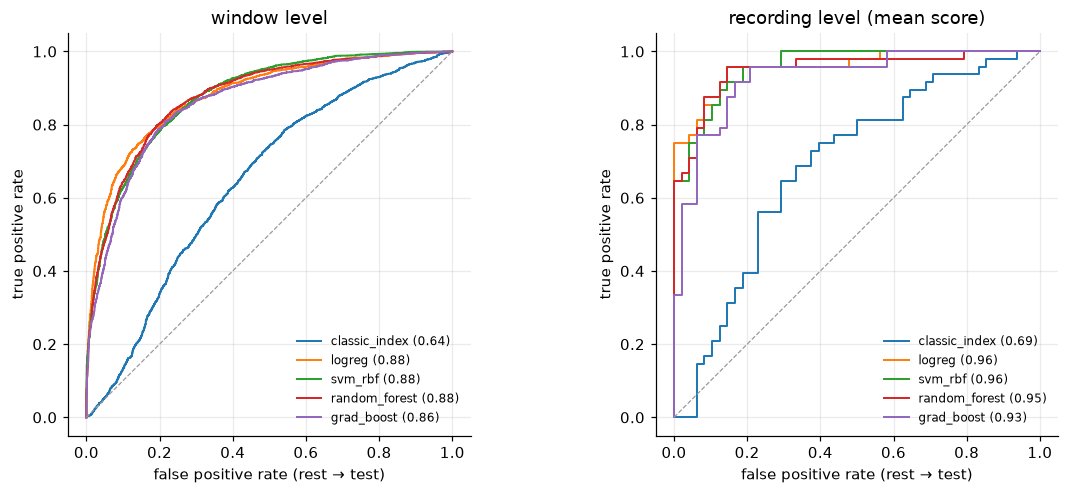

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for m in cand:
    fpr, tpr, _ = roc_curve(y, oof[m].score); axes[0].plot(fpr, tpr, lw=1.3, label=f"{m} ({metrics.loc[m, 'win_roc_auc']:.2f})")
    r = rec_tables[m]; fpr, tpr, _ = roc_curve(r.label, r.score); axes[1].plot(fpr, tpr, lw=1.3, label=f"{m} ({metrics.loc[m, 'rec_auc']:.2f})")
for ax, t in zip(axes, ["window level", "recording level (mean score)"]):
    ax.plot([0, 1], [0, 1], color="0.6", ls="--", lw=0.8); ax.set_xlabel("false positive rate (rest → test)"); ax.set_ylabel("true positive rate")
    ax.set_title(t); ax.legend(frameon=False, fontsize=8, loc="lower right"); ax.set_aspect("equal")
fig.tight_layout(); fig.savefig(FIG_DIR / "roc_curves.png", bbox_inches="tight"); plt.show()

## 4. Per-subject performance and model comparison

Each subject contributes one window-level AUC (its test windows vs its rest windows, scored by a model that never saw the subject).
We test (a) whether models beat chance across subjects (Wilcoxon signed-rank vs 0.5) and (b) pairwise differences against logistic regression
(paired Wilcoxon on per-subject AUC, Holm-corrected).

,median_subject_auc,subjects_auc_gt_0.5,subjects_auc_ge_0.8,p_vs_chance,p_vs_logreg,p_vs_logreg_holm
model,,,,,,
classic_index,0.7392,40,19,0.0,0.0000,0.0
logreg,0.9520,46,41,0.0,NaN,NaN
svm_rbf,0.9486,45,43,0.0,0.6805,1.0
random_forest,0.9386,46,42,0.0,0.8112,1.0
grad_boost,0.9520,46,41,0.0,0.6657,1.0


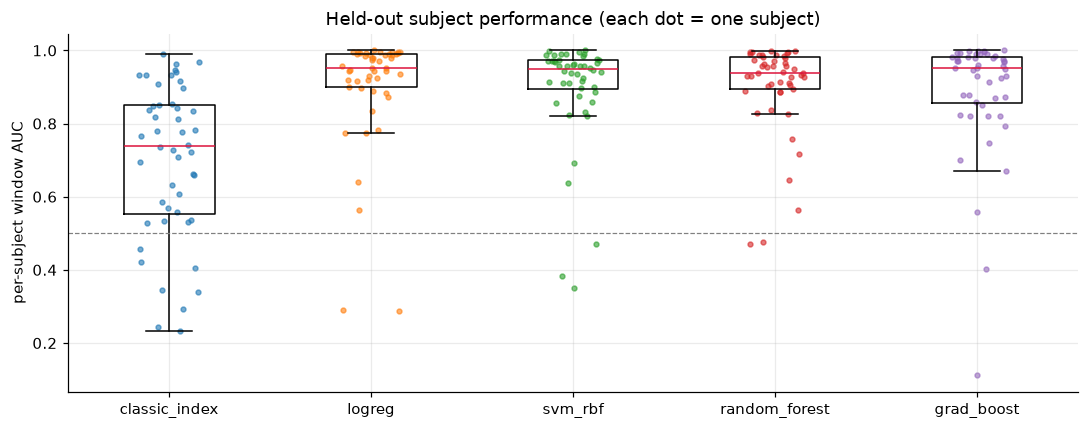

In [5]:
ps = {m: per_subject(meta, oof[m]).set_index("subject") for m in cand}
auc_s = pd.DataFrame({m: ps[m].roc_auc for m in cand})
tests = []
for m in cand:
    w0 = stats.wilcoxon(auc_s[m] - 0.5)
    row = {"model": m, "median_subject_auc": auc_s[m].median(), "subjects_auc_gt_0.5": int((auc_s[m] > 0.5).sum()),
           "subjects_auc_ge_0.8": int((auc_s[m] >= 0.8).sum()), "p_vs_chance": w0.pvalue}
    if m != "logreg":
        row["p_vs_logreg"] = stats.wilcoxon(auc_s[m], auc_s["logreg"]).pvalue
    tests.append(row)
tests = pd.DataFrame(tests).set_index("model")
mask = tests.p_vs_logreg.notna()
if mask.any():
    order = tests.loc[mask, "p_vs_logreg"].sort_values()
    holm = np.minimum(1, np.maximum.accumulate(order.values * (len(order) - np.arange(len(order)))))
    tests.loc[order.index, "p_vs_logreg_holm"] = holm
display(tests.round(4))

fig, ax = plt.subplots(figsize=(10, 4))
for i, m in enumerate(cand):
    v = auc_s[m].values
    ax.scatter(np.full(len(v), i) + np.random.default_rng(i).uniform(-.15, .15, len(v)), v, s=10, alpha=0.6)
    ax.boxplot(v, positions=[i], widths=0.45, showfliers=False, medianprops=dict(color="crimson"))
ax.axhline(0.5, color="0.5", ls="--", lw=0.8); ax.set_xticks(range(len(cand)), cand); ax.set_ylabel("per-subject window AUC")
ax.set_title("Held-out subject performance (each dot = one subject)")
fig.tight_layout(); fig.savefig(FIG_DIR / "per_subject_auc.png", bbox_inches="tight"); plt.show()

## 5. Label-permutation test

Is the best AUC distinguishable from what the pipeline achieves on data with no real label information? We permute labels **within subject**
(randomly swap which of a subject's two recordings is called "test"), preserving the recording structure, and rerun the full cross-validation
with fixed hyper-parameters (logistic regression, C = the value chosen most often in notebook 04). The p-value is $(1 + \#\{AUC_{perm} \geq AUC_{obs}\})/(1+N)$.

LR (C=0.01) observed window AUC 0.888; null mean 0.491, 95th pct 0.583, max 0.639; p = 0.010


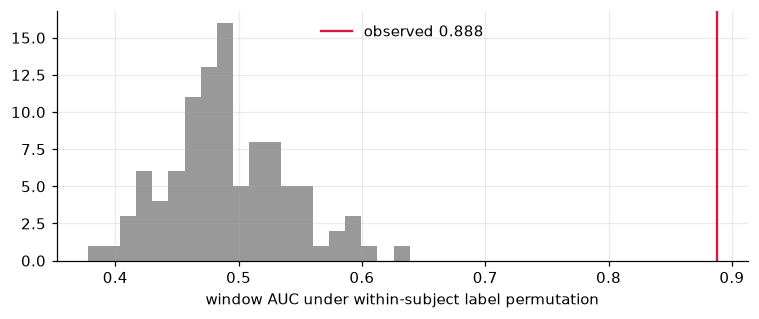

In [6]:
bp = P[P.model == "logreg"].copy()
best_params = json.load(open(ROOT / "results" / "04_modeling" / "summary.json"))["best_params_per_fold"]["logreg"]
C_mode = pd.Series([eval(b)["clf__C"] for b in best_params]).mode()[0]
LR = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=C_mode, max_iter=5000))
obs = roc_auc_score(y, fixed_cv(LR, X, y, groups).score)

def perm_auc(seed):
    rng = np.random.default_rng(seed)
    flip = {s: rng.random() < 0.5 for s in np.unique(groups)}
    yp = np.array([1 - l if flip[s] else l for s, l in zip(groups, y)])
    return roc_auc_score(yp, fixed_cv(LR, X, yp, groups).score)

N_PERM = 100
null = np.array(Parallel(n_jobs=10)(delayed(perm_auc)(1000 + i) for i in range(N_PERM)))
p_perm = (1 + (null >= obs).sum()) / (1 + N_PERM)
print(f"LR (C={C_mode}) observed window AUC {obs:.3f}; null mean {null.mean():.3f}, 95th pct {np.percentile(null, 95):.3f}, max {null.max():.3f}; p = {p_perm:.3f}")
fig, ax = plt.subplots(figsize=(7, 3)); ax.hist(null, bins=20, color="0.6"); ax.axvline(obs, color="crimson", label=f"observed {obs:.3f}")
ax.set_xlabel("window AUC under within-subject label permutation"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "permutation_test.png", bbox_inches="tight"); plt.show()

## 6. Feature importance

Two complementary views, both computed only from models evaluated on held-out subjects:

1. **Grouped permutation importance** on each outer test fold: jointly shuffle all columns of a feature group (or all 20 features of one channel) and
   measure the drop in AUC. Grouping is necessary because features are strongly collinear — permuting one feature while its near-duplicate stays intact
   would understate its importance.
2. **Logistic-regression coefficients** (standardised features) across the 8 outer-fold fits, aggregated as mean |coef| per group. The across-fold
   standard deviation shows stability.

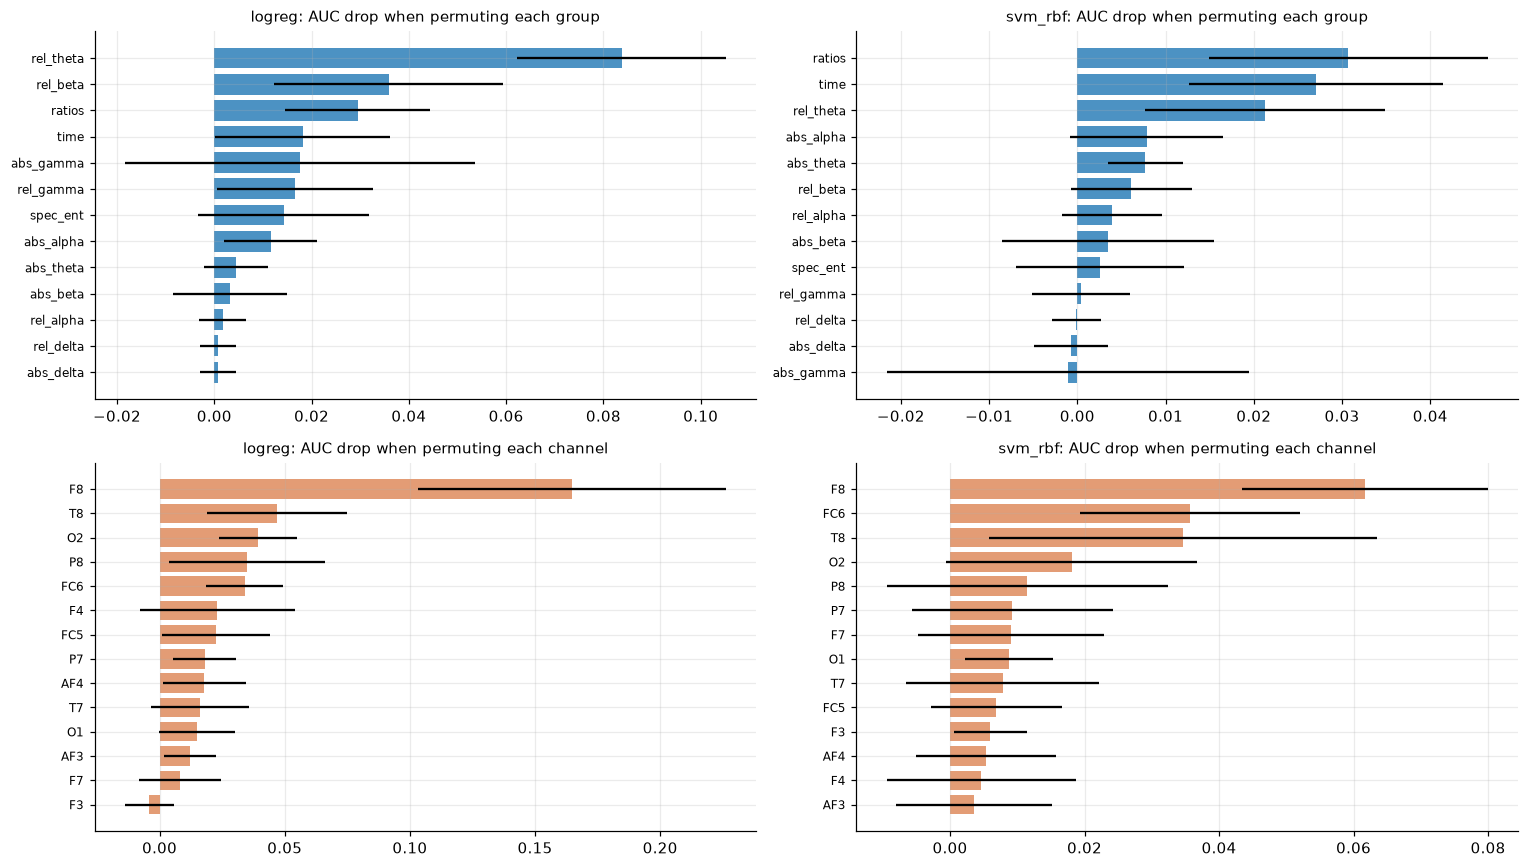

,mean_abs_coef,sd_across_folds
rel_theta,0.139,0.005
abs_alpha,0.114,0.007
abs_gamma,0.109,0.007
rel_gamma,0.106,0.007
abs_theta,0.096,0.005
rel_beta,0.095,0.004
spec_ent,0.093,0.004
abs_beta,0.088,0.008
ratios,0.084,0.003
time,0.083,0.003


largest mean LR coefficients (+ = pushes toward 'test'):


,F8_abs_alpha,F8_abs_gamma,O2_rel_theta,F8_abs_beta,O1_rel_theta,T8_mobility,T8_rel_beta,FC6_mobility,F8_rel_theta,F8_log_var,F8_rel_beta,F8_mobility,F8_spec_ent,P8_rel_gamma,P7_rel_alpha
coef,0.449,0.376,0.344,0.336,0.285,-0.271,-0.256,-0.255,0.254,0.251,-0.248,-0.241,0.238,0.235,0.231


In [7]:
grp = feature_groups(X.columns)
by_channel = {ch: [c for c in X.columns if channel_of(c) == ch] for ch in CHANNELS}
best_nl = metrics.loc[["random_forest", "grad_boost", "svm_rbf"], "win_roc_auc"].idxmax()
spec = model_specs()[best_nl]
nl_params = json.load(open(ROOT / "results" / "04_modeling" / "summary.json"))["best_params_per_fold"][best_nl]

def fold_importance(fold, tr, te, model_name):
    if model_name == "logreg":
        est = clone(LR)
    else:
        est = clone(spec.estimator).set_params(**eval(nl_params[fold]))
    est.fit(X.iloc[tr], y[tr])
    Xte = X.iloc[te].copy(); base = roc_auc_score(y[te], decision_scores(est, Xte))
    rng = np.random.default_rng(fold); out = {}
    for kind, gmap in (("group", grp), ("channel", by_channel)):
        for gname, cols in gmap.items():
            drops = []
            for rep in range(3):
                Xp = Xte.copy(); idx = rng.permutation(len(Xp))
                Xp[cols] = Xte[cols].values[idx]
                drops.append(base - roc_auc_score(y[te], decision_scores(est, Xp)))
            out[(kind, gname)] = np.mean(drops)
    coefs = est[-1].coef_[0] if model_name == "logreg" else None
    return out, coefs

splits = list(outer_cv(8).split(X, y, groups))
imp = {}
for mname in ("logreg", best_nl):
    res = Parallel(n_jobs=8)(delayed(fold_importance)(k, tr, te, mname) for k, (tr, te) in enumerate(splits))
    imp[mname] = pd.DataFrame([r[0] for r in res])
    if mname == "logreg":
        coefs = pd.DataFrame([r[1] for r in res], columns=X.columns)

def summarise(df, kind):
    d = df[[c for c in df.columns if c[0] == kind]]; d.columns = [c[1] for c in d.columns]
    return pd.DataFrame({"mean": d.mean(), "sd": d.std()}).sort_values("mean", ascending=False)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for j, mname in enumerate(("logreg", best_nl)):
    for i, kind in enumerate(("group", "channel")):
        s = summarise(imp[mname], kind); ax = axes[i, j]
        ax.barh(s.index[::-1], s["mean"][::-1], xerr=s["sd"][::-1], color="#1f77b4" if kind == "group" else "#DD8452", alpha=0.8)
        ax.set_title(f"{mname}: AUC drop when permuting each {kind}", fontsize=10); ax.tick_params(axis="y", labelsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "permutation_importance.png", bbox_inches="tight"); plt.show()

coef_grp = pd.DataFrame({g: coefs[cols].abs().mean(axis=1) for g, cols in grp.items()})
coef_summary = pd.DataFrame({"mean_abs_coef": coef_grp.mean(), "sd_across_folds": coef_grp.std()}).sort_values("mean_abs_coef", ascending=False)
top_coef = coefs.mean().reindex(coefs.mean().abs().sort_values(ascending=False).index).head(15)
display(coef_summary.round(3)); print("largest mean LR coefficients (+ = pushes toward 'test'):"); display(top_coef.round(3).to_frame("coef").T)
imp_tables = {m: {k: summarise(imp[m], k) for k in ("group", "channel")} for m in imp}

## 7. Confound analysis: is the classifier reading brain state or artifacts?

Stage 1–2 showed the test recordings carry more ocular/muscle artifact. Feature-subset ablations (same CV, fixed hyper-parameters) quantify how much
performance depends on artifact-prone inputs:

| Subset | Content | Interpretation if AUC stays high |
|---|---|---|
| all | 282 features | reference |
| no eye-adjacent | drop AF3, AF4, F7, F8 | performance does not hinge on the electrodes nearest the eyes |
| posterior only | O1, O2, P7, P8 | furthest from eyes / jaw muscles |
| θ/α/β spectral | absolute & relative θ, α, β + ratios | excludes δ (ocular) and γ (EMG) and the time-domain shape features |
| θ/α/β posterior | the previous restricted to O1, O2, P7, P8 | the most conservative "neural" subset |
| artifact proxies | kurtosis, skewness, line length, δ and γ power | performance of artifact markers alone — an upper bound for an "artifact detector" |

n_features           win_auc           rec_acc       
model            grad_boost logreg grad_boost logreg grad_boost logreg
subset                                                                
all                   282.0  282.0      0.870  0.888      0.885  0.896
no eye-adjacent       201.0  201.0      0.847  0.851      0.854  0.844
posterior only         80.0   80.0      0.811  0.816      0.844  0.854
θ/α/β spectral        128.0  128.0      0.879  0.896      0.896  0.917
θ/α/β posterior        36.0   36.0      0.801  0.805      0.865  0.865
artifact proxies       98.0   98.0      0.804  0.808      0.823  0.771

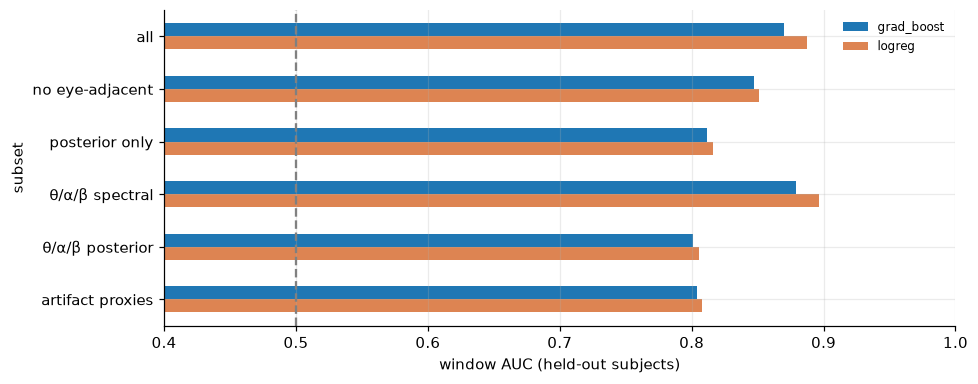

In [8]:
EYE = {"AF3", "AF4", "F7", "F8"}; POST = {"O1", "O2", "P7", "P8"}
def is_tab(c):
    n = c.split("_", 1)[1] if channel_of(c) else c
    return n.startswith(("abs_theta", "abs_alpha", "abs_beta", "rel_theta", "rel_alpha", "rel_beta", "r_")) or n in ("fT_pA", "faa_F4F3")
def is_art(c):
    n = c.split("_", 1)[1] if channel_of(c) else c
    return n in ("kurt", "skew", "log_ll", "abs_delta", "rel_delta", "abs_gamma", "rel_gamma")
subsets = {
    "all": list(X.columns),
    "no eye-adjacent": [c for c in X.columns if channel_of(c) not in EYE and c not in ("fT_pA",)],
    "posterior only": [c for c in X.columns if channel_of(c) in POST],
    "θ/α/β spectral": [c for c in X.columns if is_tab(c)],
    "θ/α/β posterior": [c for c in X.columns if is_tab(c) and channel_of(c) in POST],
    "artifact proxies": [c for c in X.columns if is_art(c)],
}
HGB = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.03, max_leaf_nodes=7, early_stopping=False, random_state=SEED)
def run_subset(name, cols, mname):
    est = LR if mname == "logreg" else HGB
    o = fixed_cv(est, X[cols], y, groups)
    r = recording_level(meta, o, 0.5)
    return {"subset": name, "model": mname, "n_features": len(cols), "win_auc": roc_auc_score(y, o.score),
            "win_bal_acc": balanced_accuracy_score(y, o.pred), "rec_acc": (r.pred == r.label).mean(), "rec_auc": roc_auc_score(r.label, r.score),
            "subject_auc_median": per_subject(meta, o).roc_auc.median()}
abl = pd.DataFrame(Parallel(n_jobs=6)(delayed(run_subset)(n, c, m) for n, c in subsets.items() for m in ("logreg", "grad_boost")))
display(abl.pivot(index="subset", columns="model", values=["n_features", "win_auc", "rec_acc"]).loc[list(subsets)].round(3))

fig, ax = plt.subplots(figsize=(9, 3.6))
pv = abl.pivot(index="subset", columns="model", values="win_auc").loc[list(subsets)]
pv.plot.barh(ax=ax, color=["#1f77b4", "#DD8452"]); ax.axvline(0.5, color="0.5", ls="--"); ax.invert_yaxis()
ax.set_xlabel("window AUC (held-out subjects)"); ax.set_xlim(0.4, 1); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "ablation.png", bbox_inches="tight"); plt.show()

**Residual artifact vs. score.** Within each condition, does a window's classifier score rise with its residual artifact amplitude (max |x| after
filtering)? A strong positive association inside the *rest* condition would mean the model partly scores "artifact-ness".

In [9]:
win = pd.read_csv(ROOT / "data" / "processed" / "windows.csv")
d = meta.merge(win[["subject", "condition", "start_s", "max_abs"]], on=["subject", "condition", "start_s"], how="left")
assert len(d) == len(meta) and d.max_abs.notna().all()
best_overall = metrics.drop(index=["chance", "classic_index"]).win_roc_auc.idxmax()
art = []
for m in ("logreg", best_overall):
    for c in CONDITIONS:
        sel = (meta.condition == c).values
        art.append({"model": m, "condition": CONDITIONS[c], "spearman_score_vs_max_abs": stats.spearmanr(oof[m].score[sel], d.max_abs[sel]).statistic})
art = pd.DataFrame(art).drop_duplicates(); display(art.round(3))

,model,condition,spearman_score_vs_max_abs
0,logreg,rest,0.140
1,logreg,test,0.095


## 8. Save evaluation outputs

In [10]:
def lst(t): return [float(v) for v in t]
export = {
    "metrics": {m: {"window": {k.replace("win_", ""): (float(v) if not isinstance(v, (list, tuple)) else (lst(v) if k.endswith("_ci") else v))
                               for k, v in metrics.loc[m].items() if k.startswith("win_")},
                    "recording": {"accuracy": float(metrics.loc[m, "rec_accuracy"]), "roc_auc": float(metrics.loc[m, "rec_auc"]),
                                  "f1": float(metrics.loc[m, "rec_f1"]), "confusion_matrix": metrics.loc[m, "rec_cm"]}} for m in MODELS},
    "per_subject_tests": tests.reset_index().to_dict(orient="records"),
    "permutation_test": {"model": f"logreg C={C_mode}", "observed_auc": float(obs), "null_mean": float(null.mean()),
                         "null_p95": float(np.percentile(null, 95)), "p_value": float(p_perm), "n_permutations": N_PERM},
    "ablation": abl.to_dict(orient="records"),
    "artifact_score_correlation": art.to_dict(orient="records"),
    "best_model": best_overall, "best_nonlinear": best_nl,
}
with open(OUT / "summary.json", "w") as fh:
    json.dump(export, fh, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
auc_s.to_csv(OUT / "per_subject_auc.csv")
for m, t in imp_tables.items():
    for k, s in t.items(): s.to_csv(OUT / f"importance_{m}_{k}.csv")
coef_summary.to_csv(OUT / "logreg_coef_groups.csv"); coefs.mean().to_csv(OUT / "logreg_coef_mean.csv", header=["coef"])
for m, r in rec_tables.items(): r.assign(model=m)
pd.concat([r.assign(model=m) for m, r in rec_tables.items()]).to_csv(OUT / "recording_predictions.csv", index=False)
print("saved:", *sorted(p.name for p in OUT.iterdir()))

saved: importance_logreg_channel.csv importance_logreg_group.csv importance_svm_rbf_channel.csv importance_svm_rbf_group.csv logreg_coef_groups.csv logreg_coef_mean.csv per_subject_auc.csv recording_predictions.csv summary.json


## 9. Findings and limitations

**Performance on unseen subjects.** Logistic regression: window AUC 0.881 (95 % subject-bootstrap CI 0.838–0.918), balanced accuracy 0.800,
precision 0.786, recall 0.792, specificity 0.809, F1 0.789; recording level accuracy 0.865, AUC 0.957. SVM, random forest and gradient boosting
are statistically indistinguishable from it (paired Wilcoxon on per-subject AUC, Holm-corrected p = 1.0). The classic fT/pA index (AUC 0.645) is clearly worse (p < 10⁻⁴).

**Not chance.** Within-subject label permutation (100 runs, full CV, LR C = 0.01): null AUC 0.49 ± small spread, max 0.64; observed 0.888 → p = 0.010
(the minimum attainable with 100 permutations).

**Per subject vs pooled.** Median per-subject AUC is ~0.95 (41/48 subjects ≥ 0.8), much higher than the pooled window AUC (0.88). The model ranks
a person's own windows well, but scores are shifted per person, so a single global threshold misclassifies whole recordings of some subjects. This
is the between-subject offset predicted by the η² analysis in notebook 03 and motivates baseline normalisation (notebook 06).

**Feature importance.** Grouped permutation importance and LR coefficients agree that relative θ and absolute α carry the most information,
but γ (EMG-prone) also ranks high, and the largest individual coefficients are all at **F8** (adjacent to the right eye).

**Confound analysis.** Artifact-proxy features alone (δ/γ power, kurtosis, skewness, line length) reach AUC 0.81 — about the same as posterior
θ/α/β power alone (0.80). Removing eye-adjacent channels lowers AUC to 0.85; restricting to θ/α/β spectral features slightly *raises* it (0.896).
Window scores correlate only weakly with residual artifact amplitude within condition (ρ ≈ 0.10–0.14).
Interpretation: brain-rhythm features and ocular/muscle markers carry *redundant* rest-vs-task information. The classifier is not merely an
artifact detector (posterior θ/α/β alone works), but part of the decision likely reflects eye and muscle activity, and STEW (no EOG/EMG) cannot
separate the two. For a deployment-oriented model, the θ/α/β-only subset is preferable: equal accuracy with fewer artifact-prone inputs.

**Limitations.**
- Rest vs. multitasking differs in visual stimulation, eye movements and motor activity, not only in workload.
- One session per subject: no evidence about stability across days or headset re-placement.
- Windows from one recording are correlated; effective sample size ≈ 48 subjects, so CIs are wide-ish (±0.04 AUC).
- Hyper-parameters for ablations and permutation tests were fixed (from notebook 04) rather than re-tuned; nested CV was used for the headline numbers.
- Zero-phase filtering and whole-recording bad-channel detection are offline operations; a live system would need causal equivalents.
